/var/folders/fv/19nygrx97gjfc62f5sl03gx40000gn/T/ipykernel_45245/1942619085.py:22: UserWarning: linewidths is ignored by contourf
  plt.contourf(y1, y2, Z, levels=50, linewidths=0.5)


Text(0, 0.5, 'y2')

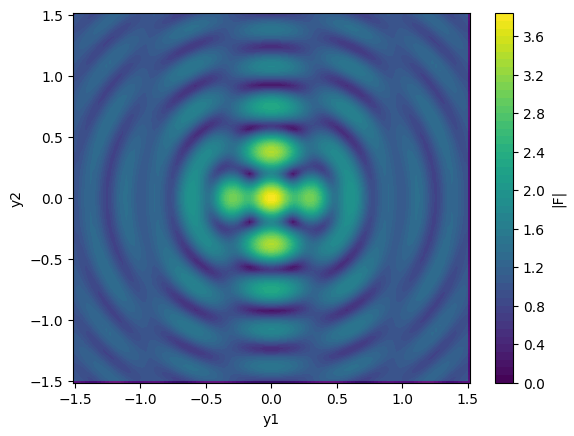

In [21]:
import numpy as np
import time
from gwlens import solver2d
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
lens = solver2d.point_mass(0.5, (-0.5, 0.0)) + solver2d.point_mass(0.5, (0.5, 0.0)) 
    # equal-mass binary
y = (0.1, 0.2)
#ws = np.linspace(0.5, 300, 1000)
ws = 10
t = time.perf_counter()
y1 = np.linspace(-1.5, 1.5, 100)
y2 = np.linspace(-1.5, 1.5, 100)
Z = np.empty((len(y2), len(y1)))          # note: rows are y2, columns are y1

for j, b in enumerate(y2):
    for i, a in enumerate(y1):
        F = solver2d.amplification(ws, (a, b), lens)
        Z[j, i] = np.abs(F)            # iw = index of your chosen w

plt.pcolormesh(y1, y2, Z, cmap='magma')
plt.contourf(y1, y2, Z, levels=50, linewidths=0.5)
plt.colorbar(label='|F|')
plt.xlabel('y1')
plt.ylabel('y2')


In [ ]:
"""
Defining your own lens for lens2d_general.py: three worked examples.

Recipe
  1. write psi(x1, x2) with analytic numpy operations (it is also called with complex arrays)
  2. list the points where psi is not smooth (point masses, cusps, very small cores)
  3. lens = G.Lens(psi, singular=[...])            # optional: q_inf = kappa + |gamma|
  4. F = G.amplification_many(ws, y, lens)          # or G.amplification(w, y, lens)
     F, err = G.amplification_many(ws, y, lens, estimate_error=True)   # self-check
"""
import time
import numpy as np
import gwlens as G


# ---------------------------------------------------------------- 1. SIE + external shear
def sie_plus_shear(b=1.0, q=0.7, phi=0.3, gamma1=0.05, gamma2=-0.03, x0=(0.0, 0.0)):
    """Singular isothermal ellipsoid (Keeton & Kochanek form) rotated by phi, plus external shear."""
    c, s, sq = np.cos(phi), np.sin(phi), np.sqrt(1 - q * q)
    a1, a2 = x0

    def psi(x1, x2):
        u = c * (x1 - a1) + s * (x2 - a2)                 # coordinates along the ellipse axes
        v = -s * (x1 - a1) + c * (x2 - a2)
        om = np.sqrt(q * q * u * u + v * v)
        ax = b * q / sq * np.arctan(sq * u / om)
        ay = b * q / sq * np.arctanh(sq * v / om)
        return u * ax + v * ay + 0.5 * (gamma1 * (x1 * x1 - x2 * x2) + 2 * gamma2 * x1 * x2)
    return G.Lens(psi, singular=[x0], q_inf=np.hypot(gamma1, gamma2))


# ---------------------------------------------------------------- 2. pseudo-elliptical NFW
def elliptical_nfw(k=2.0, psi0=1.0, e=0.15):
    """NFW potential evaluated at an elliptical radius (pseudo-elliptical NFW)."""
    def psi(x1, x2):
        R = np.sqrt((1 - e) * x1 * x1 + (1 + e) * x2 * x2 + 0j)
        v = k * R
        return 0.5 * psi0 * (np.log(v / 2)**2 + np.arccos(1 / v)**2)
    return G.Lens(psi, singular=[(0.0, 0.0)])


# ---------------------------------------------------------------- 3. host halo + subhalos (built from components)
def host_with_subhalos():
    host = G.cis(psi0=1.0, rc=0.1)
    subs = [(0.01, (1.2, 0.3)), (0.005, (-0.8, 0.9)), (0.02, (0.4, -1.1))]
    lens = host
    for m, pos in subs:
        lens = lens + G.point_mass(m, pos)
    return lens


if __name__ == "__main__":
    ws = np.linspace(0.2, 100.0, 500)
    for name, lens, y in (("SIE (q=0.7) + external shear", sie_plus_shear(), (0.15, 0.1)),
                          ("pseudo-elliptical NFW", elliptical_nfw(), (0.2, 0.1)),
                          ("cored halo + 3 point-mass subhalos", host_with_subhalos(), (0.3, 0.2))):
        mism = lens.check_analytic()
        t = time.perf_counter()
        F, err = G.amplification_many(ws, y, lens, estimate_error=True)
        dt = time.perf_counter() - t
        print(f"{name:<36} analytic check {mism:.1e} | {ws.size} frequencies, |F| from {abs(F).min():.3f} to {abs(F).max():.3f}"
              f" | self-check worst {err.max():.1e} | {dt:.1f} s incl. self-check", flush=True)

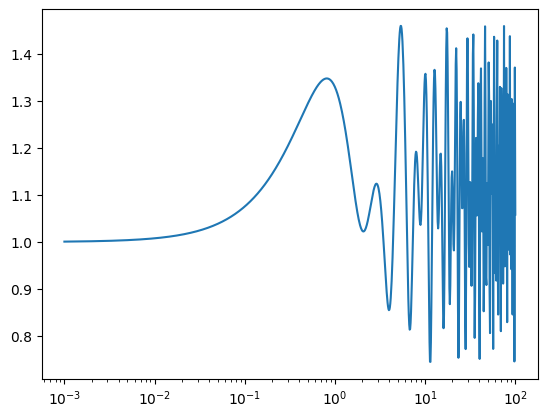

In [29]:
w = np.logspace(-3, 2, 1000)
lens = solver2d.point_mass(0.5, (-0.5, 0.0)) + solver2d.point_mass(0.5, (0.5, 0.0)) 
plt.semilogx(w, np.abs(solver2d.amplification_many(w, (1.1, 0.2), lens)), label="binary point masses")


In [29]:
"""
Amplification factor for an ARBITRARY lens potential psi(x1, x2) with the rotated-tail method.
Version 3: one solver for one or many frequencies AND one or many source positions.

    F(w, y) = w/(2 pi i) Int d^2x exp{ i w [ |x - y|^2/2 - psi(x) ] }

Quick start
-----------
    lens = Lens(my_psi, singular=[(x1a, x2a), (x1b, x2b)])       # or point_mass(...) + sis(...) + ...

    F  = amplification(w, y, lens)                    # one frequency, one source position
    Fw = amplification_many(ws, y, lens)              # many frequencies, one source position
    Fy = amplification_map(w, Y1, Y2, lens)           # one frequency, many source positions (maps)
    Fg = amplification_grid(ws, ys, lens)             # many of both: array (len(ys), len(ws))

    # or keep one solver and query it as often as you like (e.g. inside a sampler):
    s = Solver2D(lens, y=(0.1, 0.2), wmin=0.5, wmax=300, y_radius=0.3)   # all y within 0.3 of (0.1, 0.2)
    s(w, y)  s.spectrum(ws, y)  s.map(w, Y1, Y2)  s.evaluate(ws, ys)

What you supply
---------------
  psi(x1, x2)   the lens potential, called with real AND complex arrays, so analytic numpy operations
                only: + - * / **, np.log, np.sqrt, np.exp, np.arctan, np.arctanh, np.arccos, ...
                Not np.abs, np.hypot, np.arctan2, np.where, np.maximum, np.real, or if/else on x.
                If a formula needs complex intermediates on the real plane, cast to complex inside.
  singular      the points where psi is not smooth (point masses, cusps, very small cores).
  q_inf         optional: kappa + |gamma| of an external sheet / shear (< 1); estimated if omitted.

Method
------
Polar coordinates about a centre c (default: the singular point nearest the source); the radial
integral of every direction is split at r_b and its tail rotated to u_b + i t (exact, Cauchy).
Other singular points are isolated by a C-infinity partition of unity (patches in polar coordinates
about each point). Radial: Gauss-Legendre on pieces of <= 8 phase cycles (32 nodes). Angular:
trapezoid rule with a node count per radial octave from the local bandwidth.

Why both directions are fast
----------------------------
The grid is designed for a DISC of source positions |y - y_center| <= y_radius (y_radius = 0: a
single source) and for all w <= wmax. Every node then carries y- and w-independent data: position
x_j, weight W_j and A_j = |x_j|^2/2 - psi(x_j), because
        |x_j - y|^2/2 - psi(x_j) = A_j - x_j.y + |y|^2/2 .
So psi is evaluated once, and the head sum_j W_j exp(i w [A_j - x_j.y]) is
  * for many w at one y:   a 1D non-uniform FFT (FINUFFT type 3);
  * for many y at one w:   a 2D non-uniform FFT with targets w*y.
The rotated tail, per direction, is tabulated once (complex psi values on Laguerre nodes scaled by
the worst-case decay rate over the disc); per y it is interpolated in 1/w (Chebyshev), and for maps
it is turned into extra plane waves of the same 2D FFT (windowed FFT of a smooth ridge function).
Small frequencies (w < 20/u_b) use geometric frequency bands with their own fixed split.

FINUFFT (pip install finufft) is needed for many frequencies or many source positions; without it
the code falls back to direct sums (correct but much slower).

Parallel use
------------
    s = Solver2D(lens, y, wmin, wmax, y_radius=R, n_workers=None)   # None = all cores; default 1
    F = s.evaluate(ws, ys)            # rows (one spectrum per y, or one map per w) on all cores
    s.close()                         # or:  with Solver2D(...) as s: ...
    Fg = amplification_grid(ws, ys, lens, n_workers=None)

  * n_workers is an upper limit: processes are used only where they are predicted to pay off, so
    n_workers > 1 does not slow down cheap lenses (e.g. a binary, whose grid takes ~0.3 s).
  * Building the solver: psi is evaluated on the grid by up to n_workers processes (tasks write into
    shared memory; the grid is bit-identical to a serial build). Worth it for expensive potentials
    (many subhalos, elliptical profiles, ...).
  * evaluate(ws, ys): rows are distributed over a pool of processes (one FINUFFT thread each),
    started on first use and kept until close(). Worth it for many rows (>= about the core count).
  * A single call s(w, y), s.spectrum(ws, y) or s.map(w, ...) is one FINUFFT transform; it uses
    FINUFFT's own threads (threads=None: all cores; threads=k: k).
  * In a sampler with its own process pool (bilby npool, multiprocessing, ...) keep n_workers=1:
    the solver then uses one thread per process automatically (forked or daemonic processes).
  * Processes are started with 'fork' (Linux, macOS), so the lens may contain lambdas and
    closures; where fork is unavailable (Windows) everything runs serially.
"""
import os
import time
import mmap
import signal
import weakref
import warnings
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from concurrent.futures.process import BrokenProcessPool
from contextlib import contextmanager
from functools import partial
import numpy as np
from scipy.special import roots_legendre, roots_laguerre, expit
try:
    import finufft                      # needed for fast many-frequency / many-position sums
except ImportError:
    finufft = None
try:
    import numexpr as ne                # optional: multithreaded elementwise work
except ImportError:
    ne = None

_GL, _LAG = {}, {}


# ================================================================== parallel helpers
# Processes are started with 'fork', so workers inherit the lens (which may hold lambdas) and the
# finished grid without any pickling. Two rules keep this safe:
#  * a forked process must not start OpenMP threads if its parent already did (GNU libgomp then
#    deadlocks), so FINUFFT runs with one thread in every forked process;
#  * worker processes never start processes of their own.
_IMPORT_PID = os.getpid()
_NE_SET = {}
_WORKER = {}


def available_cores():
    """Number of CPU cores this process may use."""
    try:
        return len(os.sched_getaffinity(0))
    except AttributeError:
        return os.cpu_count() or 1


def _forked():
    return os.getpid() != _IMPORT_PID


def _can_fork():
    return "fork" in mp.get_all_start_methods() and not mp.current_process().daemon


@contextmanager
def _quiet_fork():
    with warnings.catch_warnings():         # Python >= 3.12 warns about fork() in threaded processes
        warnings.filterwarnings("ignore", message=r".*use of fork\(\) may lead to deadlocks.*")
        yield


def _fork_executor(n, initializer, initargs):
    return ProcessPoolExecutor(n, mp_context=mp.get_context("fork"), initializer=initializer, initargs=initargs)


def _buffer(n, dtype, shared):
    """Array of n elements; with shared=True in anonymous shared memory that forked workers write into."""
    n = int(n)
    if not shared or n == 0:
        return np.empty(n, dtype=dtype)
    return np.frombuffer(mmap.mmap(-1, n * np.dtype(dtype).itemsize), dtype=dtype, count=n)


def _set_ne_threads(n):
    if ne is not None and _NE_SET.get(os.getpid()) != n:
        ne.set_num_threads(n)
        _NE_SET[os.getpid()] = n


def _worker_common():
    signal.signal(signal.SIGINT, signal.SIG_IGN)          # Ctrl-C is handled by the parent
    _set_ne_threads(1)


def _init_fn_worker(fn):
    _worker_common()
    _WORKER["fn"] = fn


def _call_fn(i):
    return _WORKER["fn"](i)


def _pmap(fn, n, nproc):
    """[fn(0), ..., fn(n-1)] computed by nproc forked processes. fn may be a closure (it is inherited,
    not pickled); its return values are pickled back, so keep them small or write to _buffer arrays."""
    if nproc <= 1:
        return [fn(i) for i in range(n)]
    ex = _fork_executor(nproc, _init_fn_worker, (fn,))
    try:
        with _quiet_fork():
            return list(ex.map(_call_fn, range(n)))
    finally:
        ex.shutdown(wait=True, cancel_futures=True)


# Cost model for deciding whether processes pay off (deliberately pessimistic, so that n_workers > 1
# is never noticeably slower than serial): starting a worker costs _SPAWN_COST seconds, and each extra
# process adds _PAR_EFF of a core (memory bandwidth and turbo clocks are shared).
_SPAWN_COST, _PAR_EFF, _MIN_GAIN = 0.02, 0.75, 0.8
_THREAD_EFF = 0.5            # FINUFFT threads on one transform: ~half the cores' worth (assumed)


def _choose_nproc(t_serial, n_items, pmax):
    """Process count minimising the predicted time of t_serial seconds of work in n_items pieces."""
    best_p, best_t = 1, t_serial
    for p in range(2, min(pmax, n_items) + 1):
        t = t_serial / (1 + _PAR_EFF * (p - 1)) + _SPAWN_COST * (p + 1)
        if t < best_t:
            best_p, best_t = p, t
    return best_p if best_t < _MIN_GAIN * t_serial else 1


def _adaptive_map(fn, work, pmax, calib=0.03, before_fork=None):
    """[fn(i) for i in range(len(work))], work[i] = relative cost of item i. Items run here until
    `calib` seconds have passed; that measured speed predicts the rest, which goes to forked processes
    only if the cost model says it is clearly faster (before_fork(i_done) is called first).
    Returns (results, processes used)."""
    n, out, done, i = len(work), [], 0.0, 0
    t0 = time.perf_counter()
    while i < n:
        out.append(fn(i))
        done += work[i]
        i += 1
        if pmax > 1 and time.perf_counter() - t0 >= calib:
            break
    if i == n:
        return out, 1
    t_rest = (time.perf_counter() - t0) * sum(work[i:]) / max(done, 1e-300)
    p = _choose_nproc(t_rest, n - i, pmax)
    if p > 1:
        if before_fork is not None:
            before_fork(i)
        return out + _pmap(lambda k: fn(i + k), n - i, p), p
    return out + [fn(k) for k in range(i, n)], 1


def _init_eval_worker(ref):
    _worker_common()
    try:                                                  # one BLAS / OpenMP thread per worker
        from threadpoolctl import threadpool_limits
        _WORKER["limits"] = threadpool_limits(1)
    except Exception:
        pass
    s = ref()
    s._pool = s._pool_fin = s._pool_pid = None            # the parent's pool is not ours
    s.n_workers, s.threads = 1, 1
    _WORKER["solver"] = s


def _eval_rows(task):
    """Worker: rows of Solver2D.evaluate. by_y: one spectrum per source position; else one map per w."""
    s = _WORKER["solver"]
    by_y, ws, ys = task
    if by_y:
        return np.array([s.spectrum(ws, y) for y in ys]).reshape(len(ys), ws.size)
    return np.array([s.map(w, ys[:, 0], ys[:, 1]) for w in ws]).reshape(ws.size, len(ys)).T


def _shutdown_pool(ex, pid):
    if os.getpid() == pid:
        ex.shutdown(wait=True, cancel_futures=True)


def _gl(n):
    if n not in _GL:
        _GL[n] = roots_legendre(n)
    return _GL[n]


def _lag(n):
    if n not in _LAG:
        _LAG[n] = roots_laguerre(n)
    return _LAG[n]


def _unique_points(pts, tol=1e-12):
    out = []
    for p in pts:
        p = (float(p[0]), float(p[1]))
        if not any(np.hypot(p[0] - q[0], p[1] - q[1]) < tol for q in out):
            out.append(p)
    return out


# ================================================================== lens objects
class Lens:
    """A lens potential psi(x1, x2) plus the list of its singular points.

    psi       callable psi(x1, x2) -> array; analytic operations only (see module docstring)
    singular  iterable of (x1, x2) points where psi is not smooth
    q_inf     kappa + |gamma| of external sheet / shear (None: estimate automatically)
    """

    def __init__(self, psi, singular=(), q_inf=None):
        self._terms = [psi]
        self.singular = _unique_points(singular)
        self.q_inf = q_inf
        self._checked = False

    def psi(self, x1, x2):
        out = self._terms[0](x1, x2)
        for f in self._terms[1:]:
            out = out + f(x1, x2)
        return out

    __call__ = psi

    def __add__(self, other):
        new = Lens.__new__(Lens)
        new._terms = self._terms + other._terms
        new.singular = _unique_points(self.singular + other.singular)
        new.q_inf = None if (self.q_inf is None or other.q_inf is None) else self.q_inf + other.q_inf
        new._checked = False
        return new

    def grad(self, x1, x2, h=1e-20):
        """(d psi/d x1, d psi/d x2) at real points by the complex step (exact to rounding)."""
        x1 = np.asarray(x1, dtype=float)
        x2 = np.asarray(x2, dtype=float)
        g1 = np.imag(self.psi(x1 + 1j * h, x2 + 0j)) / h
        g2 = np.imag(self.psi(x1 + 0j, x2 + 1j * h)) / h
        return g1, g2

    def check_analytic(self, n=400, seed=0, verbose=False):
        """Compare complex-step and finite-difference gradients at random points.
        A mismatch means psi uses a non-analytic operation (abs, hypot, arctan2, where, ...),
        which would make the rotated tail wrong. Returns the worst relative mismatch."""
        rng = np.random.default_rng(seed)
        P = np.array(self.singular) if self.singular else np.zeros((1, 2))
        c = P.mean(axis=0)
        R = 2.0 + np.max(np.hypot(*(P - c).T))
        x = c + rng.uniform(-R, R, size=(n, 2))
        dmin = np.min(np.hypot(x[:, None, 0] - P[None, :, 0], x[:, None, 1] - P[None, :, 1]), axis=1)
        x = x[dmin > 0.05]
        with np.errstate(all="ignore"):
            try:
                g1, g2 = self.grad(x[:, 0], x[:, 1])
            except TypeError as err:
                raise TypeError("psi(x1, x2) must accept complex arrays (it is evaluated on the "
                                f"rotated tail); use analytic numpy operations only. ({err})") from None
            h = 1e-6
            f = lambda a, b: np.real(self.psi(a + 0j, b + 0j))
            d1 = (f(x[:, 0] + h, x[:, 1]) - f(x[:, 0] - h, x[:, 1])) / (2 * h)
            d2 = (f(x[:, 0], x[:, 1] + h) - f(x[:, 0], x[:, 1] - h)) / (2 * h)
            im = np.imag(self.psi(x[:, 0] + 0j, x[:, 1] + 0j))
            re = np.real(self.psi(x[:, 0] + 0j, x[:, 1] + 0j))
        mism = np.max(np.hypot(g1 - d1, g2 - d2) / (1 + np.hypot(d1, d2)))
        imag = np.max(np.abs(im) / (1 + np.abs(re)))
        bad = (not np.isfinite(mism)) or mism > 1e-5 or imag > 1e-10
        if bad:
            warnings.warn(
                f"psi does not look analytic (gradient mismatch {mism:.1e}, imaginary part on the "
                f"real plane {imag:.1e}). Use only analytic numpy operations (no abs/hypot/"
                "arctan2/where/real/if-else on x); otherwise the rotated tail is invalid.")
        if verbose:
            print(f"check_analytic: gradient mismatch {mism:.1e}, Im psi on real plane {imag:.1e}")
        self._checked = True
        return mism


# ------------------------------------------------------------------ ready-made components
def point_mass(m=1.0, x0=(0.0, 0.0)):
    """psi = m ln|x - x0|."""
    a, b, m = float(x0[0]), float(x0[1]), float(m)
    return Lens(lambda x1, x2: 0.5 * m * np.log((x1 - a)**2 + (x2 - b)**2), singular=[(a, b)], q_inf=0.0)


def sis(psi0=1.0, x0=(0.0, 0.0)):
    """psi = psi0 |x - x0|."""
    a, b, p = float(x0[0]), float(x0[1]), float(psi0)
    return Lens(lambda x1, x2: p * np.sqrt((x1 - a)**2 + (x2 - b)**2), singular=[(a, b)], q_inf=0.0)


def cis(psi0=1.0, rc=0.05, x0=(0.0, 0.0)):
    """Cored isothermal sphere (GLoW convention): psi0 [s + rc ln(2 rc/(s + rc))], s = sqrt(R^2 + rc^2).
    The centre is listed as a singular point so that a small core is resolved like a cusp."""
    a, b, p, rc = float(x0[0]), float(x0[1]), float(psi0), float(rc)

    def f(x1, x2):
        R2 = (x1 - a)**2 + (x2 - b)**2
        if rc == 0:
            return p * np.sqrt(R2)
        s = np.sqrt(R2 + rc * rc)
        return p * (s + rc * np.log(2 * rc / (s + rc)))
    return Lens(f, singular=[(a, b)], q_inf=0.0)


def nfw(k=1.0, psi0=1.0, x0=(0.0, 0.0)):
    """NFW: 0.5 psi0 [ln^2(v/2) + arccos^2(1/v)], v = k |x - x0|  (k = xi0 / r_s)."""
    a, b, p, k = float(x0[0]), float(x0[1]), float(psi0), float(k)

    def f(x1, x2):
        v = k * np.sqrt((x1 - a)**2 + (x2 - b)**2 + 0j)       # complex: arccos(1/v) for v < 1
        return 0.5 * p * (np.log(v / 2)**2 + np.arccos(1 / v)**2)
    return Lens(f, singular=[(a, b)], q_inf=0.0)


def external_shear(gamma1=0.0, gamma2=0.0, kappa=0.0):
    """psi = kappa |x|^2/2 + [gamma1 (x1^2 - x2^2) + 2 gamma2 x1 x2]/2."""
    g1, g2, k = float(gamma1), float(gamma2), float(kappa)
    f = lambda x1, x2: 0.5 * (k * (x1 * x1 + x2 * x2) + g1 * (x1 * x1 - x2 * x2) + 2 * g2 * x1 * x2)
    return Lens(f, singular=[], q_inf=k + np.hypot(g1, g2))


# ================================================================== helpers
def _step(s, s0, b=2.5):
    """C-infinity step: 1 for s <= s0, 0 for s >= 1.
    Planck taper 1/(1 + exp(b [1/(1-t) - 1/t])), t = (s - s0)/(1 - s0); b = 2.5 minimises the
    number of Fourier modes (hence trapezoid angles) needed to resolve it to ~1e-12."""
    t = np.clip((np.asarray(s, dtype=float) - s0) / (1.0 - s0), 0.0, 1.0)
    inner = (t > 0) & (t < 1)
    tt = np.where(inner, t, 0.5)
    z = b * (1.0 / (1.0 - tt) - 1.0 / tt)
    return np.where(t <= 0, 1.0, np.where(t >= 1, 0.0, expit(-z)))


def _estimate_q_inf(lens, c):
    th = np.linspace(0, 2 * np.pi, 257)[:-1]
    q = -np.inf
    for R in (1e3, 1e4):
        g1, g2 = lens.grad(c[0] + R * np.cos(th), c[1] + R * np.sin(th))
        q = max(q, np.max((np.cos(th) * g1 + np.sin(th) * g2) / R))
    return float(q)



# ================================================================== grid building blocks
def _probe_V1(lens, c, yc, u_floor, u_lin, u_hi, wmax, weight=None, n_ang=64):
    """Worst-direction accumulated phase per unit w, V1(u), on a probe grid in [u_floor, u_hi].
    Dense (>= 3 points per cycle at wmax) up to u_lin, geometric everywhere."""
    n_lin = int(max(1500, 3 * wmax * u_lin / (2 * np.pi)))
    ug = np.unique(np.concatenate([np.linspace(u_floor, u_lin, n_lin),
                                   np.geomspace(u_floor, u_hi, 3000)]))
    xg = np.sqrt(2 * ug)
    th = (np.arange(n_ang) + 0.5) * 2 * np.pi / n_ang
    dV = np.zeros(ug.size - 1)
    step = max(1, int(1_000_000 // ug.size))
    with np.errstate(all="ignore"):
        for s in range(0, n_ang, step):
            t = th[s:s + step, None]
            x1, x2 = c[0] + xg[None, :] * np.cos(t), c[1] + xg[None, :] * np.sin(t)
            ph = ug[None, :] - xg[None, :] * (yc[0] * np.cos(t) + yc[1] * np.sin(t)) - np.real(lens.psi(x1, x2))
            d = np.abs(np.diff(ph, axis=1))
            ok = np.isfinite(d)
            if weight is not None:
                m = weight(x1, x2) != 0
                ok &= m[:, 1:] & m[:, :-1]
            dV = np.maximum(dV, np.max(np.where(ok, d, 0.0), axis=0))
    return ug, np.concatenate([[0.0], np.cumsum(dV)])


def _max_dpsi_dth(lens, c, r_lo, r_hi, weight=None, n_ang=256, n_r=8):
    """max over the annulus of |d psi / d theta| (angular derivative about c), masked by weight != 0."""
    rs = np.linspace(max(r_lo, 1e-6 * r_hi), r_hi, n_r)
    R, T = np.meshgrid(rs, (np.arange(n_ang) + 0.5) * 2 * np.pi / n_ang)
    x1, x2 = c[0] + R * np.cos(T), c[1] + R * np.sin(T)
    with np.errstate(all="ignore"):
        g1, g2 = lens.grad(x1, x2)
        d = np.abs(R * (-np.sin(T) * g1 + np.cos(T) * g2))
        ok = np.isfinite(d)
        if weight is not None:
            ok &= weight(x1, x2) != 0
    return float(np.max(np.where(ok, d, 0.0)))


def _even(n):
    return int(2 * np.ceil(n / 2))


def _cheb_points(n):
    k = np.arange(n)
    return np.cos(np.pi * (k + 0.5) / n)


def _bary_matrix(xc, xe):
    """Barycentric interpolation matrix from Chebyshev points (first kind) xc to points xe."""
    n = xc.size
    wts = (-1.0) ** np.arange(n) * np.sin(np.pi * (np.arange(n) + 0.5) / n)
    d = xe[:, None] - xc[None, :]
    exact = np.isclose(d, 0.0, atol=1e-15)
    d[exact] = 1.0
    M = wts[None, :] / d
    M /= M.sum(axis=1, keepdims=True)
    rows = np.any(exact, axis=1)
    M[rows] = exact[rows].astype(float)
    return M


_WARNED = set()


def _warn_once(key, msg):
    if key not in _WARNED:
        _WARNED.add(key)
        warnings.warn(msg)


# ================================================================== the solver
class Solver2D:
    """Lens grid for all source positions |y' - y| <= y_radius and all frequencies wmin <= w <= wmax.

    lens          a Lens (see module docstring)
    y             centre of the source region (with y_radius = 0: the source position)
    wmin, wmax    frequency range the grid must resolve
    y_radius      radius of the source region (0: a single source position)

    Evaluation (all reuse the same grid; psi is never evaluated again for the head):
      s(w, y=None)            F at one frequency, one source position (default: the centre)
      s.spectrum(ws, y=None)  many frequencies, one source position     -> 1D non-uniform FFT
      s.map(w, Y1, Y2)        one frequency, many source positions       -> 2D non-uniform FFT
      s.evaluate(ws, ys)      table (len(ys), len(ws)); loops over whichever axis is shorter

    Accuracy/tuning options (defaults are the validated ones): center, patch_frac, patch_max, s0,
    cycles, ngl, nlag, n_cheb, theta_factor (2 = convergence test), bw_factor, bw_margin,
    xb_min (move split out = convergence test), xb_base, n_transition, pou_density,
    map_ext (grid built for radius map_ext*y_radius so maps are valid up to y_radius; use 1.0 if
    you never call map(), e.g. in parameter estimation - the grid is then smaller),
    nufft_eps (FINUFFT tolerance; default 1e-14 gives ~1e-12 in F),
    low_band_ratio (width of the geometric frequency bands below w = 20/u_b).

    Parallelism
      n_workers   maximum number of processes (1: none; None: all cores). Used to evaluate psi on the
                  grid while the solver is built, and by evaluate() to compute rows in parallel -
                  but only where it pays: the build times its first tasks and starts processes only
                  if a cost model predicts a clear gain (cheap lenses such as a binary usually stay
                  serial); evaluate() uses processes only when there are >= 2 rows per process and
                  enough processes to beat FINUFFT's own threads (about half the cores).
                  The pool for evaluate() is started on first use and kept; call close() or use
                  `with Solver2D(...) as s:` to stop it. Needs the 'fork' start method (Linux,
                  macOS); elsewhere, and inside daemonic pool workers, the solver runs serially.
      threads     threads per FINUFFT / numexpr call. None: library default (all cores) in the main
                  process and 1 in any forked or pool-worker process (e.g. bilby's npool workers).
    Single calls s(w, y), s.spectrum(ws, y) and s.map(w, ...) are parallelised by FINUFFT's threads.
    """

    def __init__(self, lens, y, wmin, wmax, y_radius=0.0, center=None, patch_frac=0.8, patch_max=1.0,
                 s0=0.3, cycles=8, ngl=32, nlag=30, n_cheb=None, theta_factor=1.0, bw_factor=1.3,
                 bw_margin=32, xb_min=0.0, xb_base=2.0, n_transition=3, pou_density=16.0, map_ext=1.5,
                 nufft_eps=1e-14, low_band_ratio=4.0, max_chunk=2_000_000, tail_mode=None,
                 n_workers=1, threads=None, task_nodes=262_144, min_parallel_work=400_000):
        if not lens._checked:
            lens.check_analytic()
        self.n_workers = available_cores() if (n_workers is None or n_workers <= 0) else int(n_workers)
        self.threads = None if threads is None else max(1, int(threads))
        self.task_nodes, self.min_parallel_work = int(task_nodes), int(min_parallel_work)
        self._pool = self._pool_fin = self._pool_pid = None
        self.lens = lens
        self.y0 = np.asarray(y, dtype=float)
        self.Yr = float(y_radius)
        self.ext = float(map_ext)
        self.Re = self.ext * self.Yr
        self.wmin, self.wmax = float(wmin), float(wmax)
        if not (0 < self.wmin <= self.wmax):
            raise ValueError("need 0 < wmin <= wmax")
        self.cycles, self.ngl, self.nlag = cycles, ngl, nlag
        self.theta_factor, self.bw_factor, self.bw_margin = theta_factor, bw_factor, bw_margin
        self.nufft_eps, self.max_chunk = nufft_eps, max_chunk
        self.u_floor = 1e-15 / max(self.wmax, 1.0)
        self.LX, self.LW = _lag(nlag)
        S = np.array(lens.singular, dtype=float).reshape(-1, 2)

        # ---- centre, patches, partition of unity
        if center is None:
            c = S[np.argmin(np.hypot(*(S - self.y0).T))] if len(S) else np.zeros(2)
        else:
            c = np.asarray(center, dtype=float)
        self.c = c
        self.yc0 = self.y0 - c
        self.Ymax_c = float(np.hypot(*self.yc0)) + self.Re
        patches = []
        for k, p in enumerate(S):
            if np.hypot(*(p - c)) < 1e-12:
                continue
            others = [np.hypot(*(p - q)) for j, q in enumerate(S) if j != k]
            rho = min(patch_max, patch_frac * min(others)) if others else patch_max
            patches.append((p, rho))
        self.patches = patches

        def chi0(x1, x2):
            x1, x2 = np.broadcast_arrays(x1, x2)
            out = np.ones(x1.shape)
            for p, rho in patches:                    # each bump only where it is non-zero
                d2 = (x1 - p[0])**2 + (x2 - p[1])**2
                m = d2 < rho * rho
                if m.any():
                    out[m] -= _step(np.sqrt(d2[m]) / rho, s0)
            return out
        chi0 = chi0 if patches else None

        # ---- split radius valid for every y in the (extended) disc
        q = lens.q_inf if lens.q_inf is not None else _estimate_q_inf(lens, c)
        if q >= 1:
            raise ValueError(f"kappa + |gamma| = {q:.3f} >= 1: the tail cannot be rotated upward in every direction.")
        thr = max(0.5, 0.5 * (1 + q))
        th = np.linspace(0, 2 * np.pi, 257)[:-1]
        reach = max([np.hypot(*(p - c)) + rho for p, rho in patches], default=0.0)
        xb = max(float(xb_base), 2 * self.Ymax_c, 1.25 * reach, float(xb_min))
        for _ in range(400):
            g1, g2 = lens.grad(c[0] + xb * np.cos(th), c[1] + xb * np.sin(th))
            if np.max((np.cos(th) * (self.yc0[0] + g1) + np.sin(th) * (self.yc0[1] + g2) + self.Re) / xb) <= thr:
                break
            xb *= 1.1
        else:
            raise RuntimeError("could not find a split radius; is the potential growing faster than r^2/2?")
        self.q_inf, self.xb0, self.ub0 = q, xb, xb * xb / 2
        self.w_switch = 20 / self.ub0
        self.ub_max = max(self.ub0, 20 / self.wmin)

        self.D_out = _max_dpsi_dth(lens, c, self.xb0 / 2, max(np.sqrt(2 * self.ub_max), self.xb0))

        extra_r, dists = [], []
        for p, rho in patches:
            d = np.hypot(*(p - c))
            n = int(np.ceil(2 * rho / ((1 - s0) * rho / n_transition)))
            extra_r.append(np.linspace(max(0.0, d - rho), d + rho, n + 1))
            dists.append((d, rho))

        def ang_req(r_lo, r_hi):
            n = 0.0
            for d, rho in dists:
                if d - rho < r_hi and d + rho > r_lo:
                    n = max(n, pou_density * 2 * np.pi * min(r_hi, d + rho) / ((1 - s0) * rho))
            return n

        def touches(r_lo, r_hi):
            return any(d - rho < r_hi and d + rho > r_lo for d, rho in dists)

        # ---- plan the head nodes (y- and w-independent): background (k = 0), then patches (k >= 1).
        # Each region: probe of the worst-direction phase variation V1(u) (+ Re dr for the y-dependent
        # part), then radial nodes and angular counts. Regions are independent -> parallel tasks.
        def plan_region(k):
            if k == 0:
                ug, V1 = _probe_V1(lens, c, self.yc0, self.u_floor, self.ub0, self.ub_max, self.wmax, weight=chi0)
                V1 = V1 + self.Re * (np.sqrt(2 * ug) - np.sqrt(2 * ug[0]))
                blocks, meta = self._plan_nodes(c, self.Ymax_c, 0.0, self.ub0, ug, V1, self.wmax, weight=chi0,
                                                touches=touches, extra_r=np.concatenate(extra_r) if extra_r else (),
                                                ang_req=ang_req if patches else None)
            else:
                p, rho = patches[k - 1]
                ug, V1 = _probe_V1(lens, p, self.y0 - p, self.u_floor, rho * rho / 2, rho * rho / 2, self.wmax)
                V1 = V1 + self.Re * (np.sqrt(2 * ug) - np.sqrt(2 * ug[0]))
                blocks, meta = self._plan_nodes(p, float(np.hypot(*(self.y0 - p))) + self.Re, 0.0, rho * rho / 2,
                                                ug, V1, self.wmax, radial_weight=lambda r: _step(r / rho, s0),
                                                extra_r=np.linspace(s0 * rho, rho, n_transition + 1))
            blocks = [(cc, r, wr, N, wgt is not None) for cc, r, wr, N, wgt in blocks]   # picklable
            return (ug, V1) if k == 0 else None, blocks, meta

        n_reg = 1 + len(patches)
        plans, _ = _adaptive_map(plan_region, [2.0] + [1.0] * len(patches), self._pmax(n_reg))
        self.ug_bg, self.V1_bg = plans[0][0]
        plans = [([(cc, r, wr, N, chi0 if use else None) for cc, r, wr, N, use in blocks], meta)
                 for _, blocks, meta in plans]
        regions = [dict(kind="background", center=tuple(c), **plans[0][1])]
        regions += [dict(kind="patch", center=tuple(p), rho=rho, **P[1]) for (p, rho), P in zip(patches, plans[1:])]
        self.D_tail = max(plans[0][1]["D_outer"], self.D_out)

        # ---- plan the frequency bands: main (u_b = ub0) and geometric low bands (u_b = 20 / w_low)
        self.bands = []
        if self.wmax >= self.w_switch:
            self.bands.append(self._plan_band(max(self.wmin, self.w_switch), self.wmax, self.ub0, n_cheb))
        if self.wmin < self.w_switch:
            hi = min(self.w_switch, self.wmax)
            while True:
                lo = max(self.wmin, hi / low_band_ratio)
                self.bands.append(self._plan_band(lo, hi, 20 / lo, n_cheb))
                if lo <= self.wmin * (1 + 1e-12):
                    break
                hi = lo

        # ---- evaluate psi on every planned node and tail point (the expensive part; parallel if allowed)
        groups = [[blk for P in plans for blk in P[0]]] + [b.pop("seg_blocks") for b in self.bands]
        filled, nproc = self._fill(groups, self.bands)
        self.hx1, self.hx2, self.hA, self.hW = filled[0]
        for b, seg in zip(self.bands, filled[1:]):
            b["seg"] = seg
        self._tcache = {}
        self.info = dict(center=tuple(c), x_b=self.xb0, q_inf=q, w_switch=self.w_switch, y_center=tuple(self.y0),
                         y_radius=self.Yr, n_head_nodes=int(self.hW.size), regions=regions,
                         bands=[(b["w_lo"], b["w_hi"], b["ub"], b["th"].size, b["seg"][0].size) for b in self.bands],
                         setup_processes=nproc)

    # ------------------------------------------------------------------ nodes of one polar region: the plan
    def _plan_nodes(self, c, Yabs, u_lo, u_hi, ug, V1, wtop, weight=None, touches=None, radial_weight=None,
                    extra_r=(), ang_req=None):
        """Radial nodes and angular counts of one polar region (psi is not evaluated on the grid here).
        Returns blocks [(c, r, w_r, N, weight or None)], one per radial octave, and a summary."""
        lens, K = self.lens, self.cycles
        rmax, rmin = np.sqrt(2 * u_hi), np.sqrt(2 * u_lo)
        V_lo, V_hi = np.interp([u_lo, u_hi], ug, V1)
        cuts = np.interp(np.arange(V_lo, V_hi, 2 * np.pi * K / wtop), V1, ug)
        if u_lo == 0:
            geo = np.geomspace(self.u_floor, u_hi, int(np.ceil(np.log(u_hi / self.u_floor))) + 1)
        else:
            geo = np.geomspace(u_lo, u_hi, int(np.ceil(np.log(u_hi / u_lo))) + 2)
        rb = rmax * 2.0 ** -np.arange(12, 0, -1)
        rb = rb[rb > rmin]
        extra_u = np.asarray(extra_r, dtype=float) ** 2 / 2
        edges = np.concatenate([[u_lo, u_hi], geo, cuts, np.linspace(u_lo, u_hi, 5), rb**2 / 2, extra_u])
        edges = np.unique(edges[(edges >= u_lo) & (edges <= u_hi)])
        GX, GW = _gl(self.ngl)
        mid, half = (edges[1:] + edges[:-1]) / 2, (edges[1:] - edges[:-1]) / 2
        uu = (mid[:, None] + half[:, None] * GX[None, :]).ravel()
        wu = (half[:, None] * GW[None, :]).ravel()
        xu = np.sqrt(2 * uu)
        if radial_weight is not None:
            wu = wu * radial_weight(xu)
            keep = wu != 0
            uu, wu, xu = uu[keep], wu[keep], xu[keep]
        band = np.searchsorted(rb, xu)
        r_lo_all, r_hi_all = np.concatenate([[rmin], rb]), np.concatenate([rb, [rmax]])
        blocks, D_outer, bands = [], 0.0, []
        for b in np.unique(band):
            sel = band == b
            wb_n, xb_n = wu[sel], xu[sel]
            r_lo, r_hi = r_lo_all[b], r_hi_all[b]
            D = _max_dpsi_dth(lens, c, r_lo, r_hi, weight)
            if b == band.max():
                D_outer = D
            n = self.bw_factor * wtop * (r_hi * Yabs + D) + self.bw_margin
            if ang_req is not None:
                n += ang_req(r_lo, r_hi)
            N = _even(n * self.theta_factor)
            bands.append((float(r_lo), float(r_hi), int(xb_n.size), N))
            use_w = weight is not None and (touches is None or touches(r_lo, r_hi))
            blocks.append((np.asarray(c, dtype=float), xb_n, wb_n, N, weight if use_w else None))
        return blocks, dict(D_outer=D_outer, bands=bands)

    # ------------------------------------------------------------------ psi on the planned nodes
    def _node_job(self, c, r, wr, N, s, e, weight, out, off):
        """Angles s..e-1 (of N) on radii r of one block: write x1, x2, A = |x|^2/2 - psi, W into out[off:]."""
        t = (2 * np.pi * np.arange(s, e) / N)[:, None]
        with np.errstate(all="ignore"):
            x1 = c[0] + r[None, :] * np.cos(t)
            x2 = c[1] + r[None, :] * np.sin(t)
            a = 0.5 * (x1 * x1 + x2 * x2) - np.real(self.lens.psi(x1, x2))
            wt = np.broadcast_to(wr[None, :] * (2 * np.pi / N), x1.shape)
            if weight is not None:
                wt = wt * weight(x1, x2)
        sl = slice(off, off + x1.size)
        out[0][sl], out[1][sl] = x1.ravel(), x2.ravel()
        out[2][sl] = np.broadcast_to(a, x1.shape).ravel()
        out[3][sl] = np.ravel(wt)

    def _tail_job(self, b, j):
        """Complex psi on the rotated tail of band b for the j-th Chebyshev value of 1/w."""
        c = self.c
        t = self.LX[None, :] * b["eps"][j] / b["al"][:, None]
        r = np.sqrt(2 * (b["ub"] + 1j * t))
        x1, x2 = c[0] + r * b["ct"][:, None], c[1] + r * b["st"][:, None]
        b["dA"][:, j, :] = 0.5 * (x1 * x1 + x2 * x2) - self.lens.psi(x1, x2) - b["A0"][:, None]
        b["dr"][:, j, :] = r - b["xb"]

    def _pmax(self, n_tasks):
        """Most processes worth considering for n_tasks independent tasks (1 = run here, serially)."""
        n = min(self.n_workers, available_cores(), int(n_tasks))
        if n <= 1:
            return 1
        if not _can_fork():
            if not mp.current_process().daemon:
                _warn_once("nofork", "n_workers > 1 needs the 'fork' start method (Linux/macOS); running serially.")
            return 1
        return n

    def _fill(self, groups, bands):
        """Evaluate psi on all planned node blocks (groups: head, then one segment per band) and on the
        tail points of every band. The work is cut into tasks of ~task_nodes points that write into
        preallocated arrays, so serial and parallel runs give bit-identical grids."""
        step = lambda r: max(1, min(self.max_chunk, self.task_nodes) // max(r.size, 1))
        sizes = [sum(N * r.size for _, r, _, N, _ in blocks) for blocks in groups]
        n_tasks = sum(-(-N // step(r)) for blocks in groups for _, r, _, N, _ in blocks) + sum(b["eps"].size for b in bands)
        work = sum(sizes) + sum(3 * b["th"].size * b["eps"].size * self.nlag for b in bands)  # complex psi ~ 3x
        pmax = self._pmax(n_tasks) if work >= self.min_parallel_work else 1
        outs = [tuple(np.empty(n_tot) for _ in range(4)) for n_tot in sizes]
        jobs, cost, meta = [], [], []
        for g, blocks in enumerate(groups):
            off = 0
            for c, r, wr, N, wgt in blocks:
                for s in range(0, N, step(r)):
                    e = min(N, s + step(r))
                    # outs[g] is looked up when the job runs: it may have moved to shared memory
                    jobs.append(lambda c=c, r=r, wr=wr, N=N, s=s, e=e, wgt=wgt, g=g, off=off:
                                self._node_job(c, r, wr, N, s, e, wgt, outs[g], off))
                    cost.append((e - s) * r.size)
                    meta.append(("node", g, off + (e - s) * r.size))
                    off += (e - s) * r.size
        for k, b in enumerate(bands):
            shape = (b["th"].size, b["eps"].size, self.nlag)
            b["dA"], b["dr"] = np.empty(shape, dtype=complex), np.empty(shape, dtype=complex)
            jobs.extend(partial(self._tail_job, b, j) for j in range(shape[1]))
            cost.extend([3 * shape[0] * shape[2]] * shape[1])
            meta.extend(("tail", k, j) for j in range(shape[1]))

        def to_shared(n_done):
            # processes will be used: move the outputs to shared memory, keeping what is already done
            # (only now, because shared pages are slower to fill than private ones)
            lim = [0] * len(outs)
            for kind, a, b_ in meta[:n_done]:
                if kind == "node":
                    lim[a] = b_
            for g, out in enumerate(outs):
                new = tuple(_buffer(x.size, float, True) for x in out)
                for x_new, x_old in zip(new, out):
                    x_new[:lim[g]] = x_old[:lim[g]]
                outs[g] = new
            for k, b in enumerate(bands):
                done_j = [j for kind, kk, j in meta[:n_done] if kind == "tail" and kk == k]
                for key in ("dA", "dr"):
                    new = _buffer(b[key].size, complex, True).reshape(b[key].shape)
                    new[:, done_j, :] = b[key][:, done_j, :]
                    b[key] = new

        _, nproc = _adaptive_map(lambda i: jobs[i](), cost, pmax, before_fork=to_shared)
        if nproc > 1:                                         # private copies of the shared tables
            for b in bands:
                b["dA"], b["dr"] = np.array(b["dA"]), np.array(b["dr"])
        filled = []
        for X1, X2, A, W in outs:                             # drop nodes outside the partition of unity
            m = W != 0
            filled.append((X1[m], X2[m], A[m], W[m]))
        return filled, nproc

    # ------------------------------------------------------------------ frequency band: segment + tail plan
    def _plan_band(self, w_lo, w_hi, ub, n_cheb):
        lens, c = self.lens, self.c
        xb = np.sqrt(2 * ub)
        if ub > self.ub0 * (1 + 1e-12):            # extra radial segment [ub0, ub] (beyond all patches)
            seg_blocks = self._plan_nodes(c, self.Ymax_c, self.ub0, ub, self.ug_bg, self.V1_bg, w_hi)[0]
        else:
            seg_blocks = []
        th0 = np.linspace(0, 2 * np.pi, 257)[:-1]
        g1, g2 = lens.grad(c[0] + xb * np.cos(th0), c[1] + xb * np.sin(th0))
        al0 = 1 - (np.cos(th0) * (self.yc0[0] + g1) + np.sin(th0) * (self.yc0[1] + g2) + self.Re) / xb
        r_far = abs(np.sqrt(2 * (ub + 1j * 40 / (w_lo * max(np.min(al0), 1e-3)))))
        N = _even((self.bw_factor * w_hi * (r_far * self.Ymax_c + self.D_tail) + self.bw_margin) * self.theta_factor)
        th = 2 * np.pi * np.arange(N) / N
        ct, st = np.cos(th), np.sin(th)
        g1, g2 = lens.grad(c[0] + xb * ct, c[1] + xb * st)
        al = 1 - (ct * (self.yc0[0] + g1) + st * (self.yc0[1] + g2) + self.Re) / xb
        if np.any(al <= 0):
            raise RuntimeError("tail does not decay in some direction; increase xb_min")
        x0 = np.stack([c[0] + xb * ct, c[1] + xb * st])
        A0 = 0.5 * (x0[0]**2 + x0[1]**2) - np.real(lens.psi(x0[0], x0[1]))
        e_lo, e_hi = 1 / w_hi, 1 / w_lo
        if e_hi - e_lo < 1e-12 * e_hi:
            eps = np.array([e_lo])
        else:
            nc = n_cheb or int(np.clip(14 + np.sqrt(w_hi / w_lo), 16, 32))
            eps = 0.5 * (e_hi + e_lo) + 0.5 * (e_hi - e_lo) * _cheb_points(nc)
        # the tables dA, dr (directions x eps x Laguerre nodes) are filled by _tail_job in _fill
        return dict(w_lo=w_lo, w_hi=w_hi, ub=ub, xb=xb, seg_blocks=seg_blocks, th=th, ct=ct, st=st, al=al, A0=A0,
                    x0=x0, eps=eps, e_lo=e_lo, e_hi=e_hi)

    def _band_of(self, w):
        for i, b in enumerate(self.bands):
            if b["w_lo"] * (1 - 1e-12) <= w <= b["w_hi"] * (1 + 1e-12):
                return i
        raise ValueError(f"w = {w} outside [{self.wmin}, {self.wmax}] of this solver")

    def _as_y(self, y):
        return self.y0 if y is None else np.asarray(y, dtype=float)

    def _check_y(self, y1, y2):
        d = np.hypot(np.asarray(y1) - self.y0[0], np.asarray(y2) - self.y0[1])
        if np.any(d > max(self.Yr, 1e-12) * (1 + 1e-9) + 1e-12):
            raise ValueError(f"source position outside |y - ({self.y0[0]:g}, {self.y0[1]:g})| <= {self.Yr:g}; "
                             "build the solver with a larger y_radius")

    def _check_w(self, wp):
        if np.any(wp < self.wmin * (1 - 1e-12)) or np.any(wp > self.wmax * (1 + 1e-12)):
            raise ValueError(f"frequencies must lie in [{self.wmin:g}, {self.wmax:g}] for this solver")

    # ------------------------------------------------------------------ threads and processes
    def _nthreads(self):
        """Threads per FINUFFT/numexpr call: None = library default (all cores)."""
        if _forked():           # OpenMP cannot start threads in a forked child of a process that used it
            if self.threads not in (None, 1):
                _warn_once("forkthreads", "threads > 1 is ignored in a forked process (OpenMP would deadlock).")
            return 1
        if self.threads is not None:
            return self.threads
        return 1 if mp.current_process().daemon else None

    def _fopts(self):
        n = self._nthreads()
        if n is None:
            return {}
        _set_ne_threads(n)
        return {"nthreads": n}

    def _get_pool(self):
        if self._pool is not None and self._pool_pid != os.getpid():     # inherited from a parent process
            self._pool = self._pool_fin = None
        if self._pool is None:
            n = max(1, min(self.n_workers, available_cores()))
            self._pool = _fork_executor(n, _init_eval_worker, (weakref.ref(self),))
            self._pool_pid = os.getpid()
            self._pool_fin = weakref.finalize(self, _shutdown_pool, self._pool, self._pool_pid)
        return self._pool

    def close(self):
        """Stop the worker processes of evaluate() (they are restarted automatically if needed)."""
        if self._pool_fin is not None:
            self._pool_fin()
        self._pool = self._pool_fin = self._pool_pid = None

    def __enter__(self):
        return self

    def __exit__(self, *exc):
        self.close()

    def __getstate__(self):                     # pickling (e.g. with cloudpickle) drops the process pool
        d = self.__dict__.copy()
        d["_pool"] = d["_pool_fin"] = d["_pool_pid"] = None
        return d

    # ------------------------------------------------------------------ sums over nodes
    def _sum_w(self, phi, W, ws):
        """sum_j W_j exp(i w phi_j) for an array of w."""
        if phi.size == 0:
            return np.zeros(ws.size, dtype=complex)
        if finufft is not None and ws.size >= 4:
            return finufft.nufft1d3(phi, W.astype(complex), ws, isign=1, eps=self.nufft_eps, **self._fopts())
        if ws.size > 20:
            _warn_once("nufft1", "finufft is not installed: frequency sums are done directly (much slower). "
                                 "pip install finufft")
        out = np.empty(ws.size, dtype=complex)
        for i, w in enumerate(ws):
            acc = 0.0 + 0.0j
            for s in range(0, phi.size, 1_000_000):
                acc += np.sum(W[s:s + 1_000_000] * np.exp(1j * w * phi[s:s + 1_000_000]))
            out[i] = acc
        return out

    def _sum_y(self, X1, X2, C, k1, k2):
        """sum_j C_j exp(-i (k1 X1_j + k2 X2_j)) for arrays of targets (k1, k2)."""
        if finufft is not None and k1.size >= 4:
            return finufft.nufft2d3(X1, X2, C, k1, k2, isign=-1, eps=self.nufft_eps, **self._fopts())
        if k1.size > 20:
            _warn_once("nufft2", "finufft is not installed: maps are summed directly (much slower). pip install finufft")
        out = np.empty(k1.size, dtype=complex)
        for i in range(k1.size):
            out[i] = np.sum(C * np.exp(-1j * (k1[i] * X1 + k2[i] * X2)))
        return out

    def _phases(self, A, x1, x2, y):
        if ne is not None and A.size > 100_000:
            return ne.evaluate("A - x1 * a - x2 * b", local_dict=dict(A=A, x1=x1, x2=x2, a=float(y[0]), b=float(y[1])))
        return A - x1 * y[0] - x2 * y[1]

    # ------------------------------------------------------------------ tail for one y: table in 1/w
    def _tail_table(self, bi, y):
        key = (float(y[0]), float(y[1]))
        hit = self._tcache.get(bi)
        if hit is not None and hit[0] == key:
            return hit[1], hit[2]
        b = self.bands[bi]
        sig = (b["ct"] * y[0] + b["st"] * y[1])[:, None, None]
        wj = (1 / b["eps"])[None, :, None]
        L = self.LX[None, None, :]
        if ne is not None:
            E3 = ne.evaluate("exp(1j * wj * (dA - dr * sig) + L)", local_dict=dict(wj=wj, dA=b["dA"], dr=b["dr"], sig=sig, L=L))
        else:
            E3 = np.exp(1j * wj * (b["dA"] - b["dr"] * sig) + L)
        Sv = E3 @ self.LW                                                    # (directions, n_cheb)
        nc = Sv.shape[1]
        if nc == 1:
            coef = Sv
        else:
            k = np.arange(nc)
            Tm = np.cos(np.outer(np.arange(nc), np.pi * (k + 0.5) / nc))
            coef = (2.0 / nc) * Sv @ Tm.T
            coef[:, 0] *= 0.5
        P = b["A0"] - b["x0"][0] * y[0] - b["x0"][1] * y[1]
        D = np.ascontiguousarray(((1j * (2 * np.pi / b["th"].size) / b["al"])[None, :] * coef.T))   # (n_cheb, directions)
        self._tcache[bi] = (key, P, D)
        return P, D

    def _tail_spectrum(self, bi, y, wb):
        b = self.bands[bi]
        P, D = self._tail_table(bi, y)
        nc = D.shape[0]
        if nc == 1:
            T = np.ones((1, wb.size))
        else:
            xx = (2 / wb - (b["e_hi"] + b["e_lo"])) / (b["e_hi"] - b["e_lo"])
            T = np.empty((nc, wb.size)); T[0] = 1.0
            T[1] = xx
            for m in range(2, nc):
                T[m] = 2 * xx * T[m - 1] - T[m - 2]
        if finufft is not None and P.size * wb.size > 60_000:
            R = finufft.nufft1d3(P, D, wb, isign=1, eps=self.nufft_eps, **self._fopts()).reshape(nc, wb.size)
        else:
            R = D @ np.exp(1j * np.outer(P, wb))
        return np.sum(R * T, axis=0) / wb

    # ------------------------------------------------------------------ public evaluation
    def spectrum(self, ws, y=None):
        """F at an array of frequencies for one source position y (default: the centre)."""
        ws = np.atleast_1d(np.asarray(ws, dtype=float))
        y = self._as_y(y)
        self._check_y(y[0], y[1])
        F = np.ones(ws.size, dtype=complex)
        pos = ws > 0
        wp = ws[pos]
        if wp.size == 0:
            return F
        self._check_w(wp)
        self._fopts()                                 # sets the numexpr thread count for this process
        total = self._sum_w(self._phases(self.hA, self.hx1, self.hx2, y), self.hW, wp)
        band_idx = np.array([self._band_of(w) for w in wp])
        for bi in np.unique(band_idx):
            sel = band_idx == bi
            b = self.bands[bi]
            if b["seg"][0].size:
                sx1, sx2, sA, sW = b["seg"]
                total[sel] += self._sum_w(self._phases(sA, sx1, sx2, y), sW, wp[sel])
            total[sel] += self._tail_spectrum(bi, y, wp[sel])
        F[pos] = wp / (2j * np.pi) * np.exp(0.5j * wp * (y @ y)) * total
        return F

    many = spectrum                                   # version-2 name

    def map(self, w, y1, y2, n_xi=512, n_cheb_sigma=48):
        """F at one frequency for source positions (y1, y2) (arrays of any common shape)."""
        w = float(w)
        y1 = np.asarray(y1, dtype=float); y2 = np.asarray(y2, dtype=float)
        shape = np.broadcast(y1, y2).shape
        y1, y2 = np.broadcast_to(y1, shape).ravel(), np.broadcast_to(y2, shape).ravel()
        self._check_y(y1, y2)
        if w == 0:
            return np.ones(shape, dtype=complex)
        self._check_w(np.array([w]))
        if self.Yr == 0:                              # single-source solver: every target is the centre
            return np.full(shape, self.spectrum([w])[0])
        bi = self._band_of(w)
        b = self.bands[bi]
        lens, c, LX, LW = self.lens, self.c, self.LX, self.LW
        X1, X2, C = [self.hx1], [self.hx2], [self.hW * np.exp(1j * w * self.hA)]
        if b["seg"][0].size:
            sx1, sx2, sA, sW = b["seg"]
            X1.append(sx1); X2.append(sx2); C.append(sW * np.exp(1j * w * sA))
        # tail: per direction a smooth ridge function g_i(sigma), sigma = n_i.y, windowed and FFT'd
        ct, st, al, xb, ub = b["ct"], b["st"], b["al"], b["xb"], b["ub"]
        Nt = ct.size
        t = LX[None, :] / (w * al[:, None])
        r = np.sqrt(2 * (ub + 1j * t))
        x1, x2 = c[0] + r * ct[:, None], c[1] + r * st[:, None]
        dA = 0.5 * (x1 * x1 + x2 * x2) - lens.psi(x1, x2) - b["A0"][:, None]
        dr = r - xb
        sig0 = ct * self.y0[0] + st * self.y0[1]
        xc = _cheb_points(n_cheb_sigma) * self.ext
        pref = (2 * np.pi / Nt) * 1j / (w * al)
        g = np.empty((Nt, n_cheb_sigma), dtype=complex)
        for l, xi in enumerate(xc):
            sig = sig0 + self.Yr * xi
            g[:, l] = pref * np.sum(LW[None, :] * np.exp(LX[None, :] + 1j * w * (dA - dr * sig[:, None])), axis=1)
        xu = -self.ext + 2 * self.ext * np.arange(n_xi) / n_xi
        B = _step(np.abs(xu) / self.ext, 1 / self.ext)
        v = (g @ _bary_matrix(xc, xu).T) * B[None, :]
        qs = np.fft.fftfreq(n_xi, 1.0 / n_xi)
        gh = (np.fft.fft(v, axis=1) / n_xi) * np.exp(1j * np.pi * qs)[None, :]
        keep = np.max(np.abs(gh), axis=0) > 1e-17 * np.max(np.abs(gh))
        qk = qs[keep]
        gam = gh[:, keep] * np.exp(1j * w * b["A0"])[:, None] * np.exp(-1j * np.pi * np.outer(sig0, qk) / (self.ext * self.Yr))
        rad = xb - np.pi * qk / (w * self.ext * self.Yr)
        X1.append((c[0] + np.outer(ct, rad)).ravel()); X2.append((c[1] + np.outer(st, rad)).ravel()); C.append(gam.ravel())
        out = self._sum_y(np.concatenate(X1), np.concatenate(X2), np.concatenate(C), w * y1, w * y2)
        F = w / (2j * np.pi) * np.exp(0.5j * w * (y1 * y1 + y2 * y2)) * out
        return F.reshape(shape)

    def evaluate(self, ws, ys):
        """Table F[k, m] = F(ws[m], ys[k]); ys has shape (K, 2). Loops over the shorter axis: one
        spectrum per source position, or one map per frequency. With n_workers > 1 the rows are
        computed by worker processes (one FINUFFT thread each)."""
        ws = np.atleast_1d(np.asarray(ws, dtype=float))
        ys = np.atleast_2d(np.asarray(ys, dtype=float))
        self._check_y(ys[:, 0], ys[:, 1])
        self._check_w(ws[ws > 0])
        by_y = ys.shape[0] <= ws.size or self.Yr == 0
        n_rows = ys.shape[0] if by_y else ws.size
        out = np.empty((ys.shape[0], ws.size), dtype=complex)
        # A serial row is one FINUFFT transform on all its threads; in a worker it runs on one thread.
        # FINUFFT's threads give at most about half the cores' worth on one transform, so processes
        # only pay off once at least that many rows run at the same time, each process getting >= 2
        # rows (which also pays for starting the processes).
        nproc = self._pmax(n_rows // 2)
        serial_threads = self._nthreads() or available_cores()
        if nproc > 1 and nproc < _THREAD_EFF * serial_threads:
            nproc = 1
        if nproc > 1:
            n_tasks = min(n_rows, 4 * nproc)
            rows = [np.arange(i, n_rows, n_tasks) for i in range(n_tasks)]   # round robin: balanced costs
            tasks = [(True, ws, ys[r]) if by_y else (False, ws[r], ys) for r in rows]
            try:
                with _quiet_fork():
                    res = list(self._get_pool().map(_eval_rows, tasks))
            except BrokenProcessPool:
                self.close()
                raise
            for r, v in zip(rows, res):
                if by_y:
                    out[r] = v
                else:
                    out[:, r] = v
        elif by_y:
            for k, y in enumerate(ys):
                out[k] = self.spectrum(ws, y)
        else:
            for m, w in enumerate(ws):
                out[:, m] = self.map(w, ys[:, 0], ys[:, 1])
        return out

    def __call__(self, w, y=None):
        return self.spectrum([w], y)[0]


# Lighter settings for parameter estimation: ~2x fewer nodes and faster sums, accuracy ~1e-7 in F
# (far below detector noise). Usage: Solver2D(lens, y, wmin, wmax, y_radius=R, map_ext=1.0, **PE_SETTINGS)
PE_SETTINGS = dict(ngl=24, nlag=24, nufft_eps=1e-9, bw_factor=1.15, bw_margin=20, pou_density=12)


# ================================================================== convenience functions
def _err_kw(s, kw):
    kw2 = dict(kw); kw2["theta_factor"] = 2 * kw.get("theta_factor", 1.0)
    kw3 = dict(kw); kw3["xb_min"] = 1.5 * s.xb0
    return kw2, kw3


def amplification(w, y, lens, estimate_error=False, return_info=False, **kw):
    """F at one frequency and one source position."""
    w = float(w)
    if w == 0:
        return 1.0 + 0.0j
    with Solver2D(lens, y, w, w, **kw) as s:
        F = s(w)
    out = [F]
    if estimate_error:
        kw2, kw3 = _err_kw(s, kw)
        out.append(max(abs(Solver2D(lens, y, w, w, **kw2)(w) - F), abs(Solver2D(lens, y, w, w, **kw3)(w) - F)))
    if return_info:
        out.append(dict(s.info, n_eval=s.info["n_head_nodes"]))
    return out[0] if len(out) == 1 else tuple(out)


def amplification_many(ws, y, lens, estimate_error=False, **kw):
    """F at many frequencies for one source position (one grid, one non-uniform FFT)."""
    ws = np.atleast_1d(np.asarray(ws, dtype=float))
    wp = ws[ws > 0]
    if wp.size == 0:
        return np.ones(ws.size, dtype=complex)
    with Solver2D(lens, y, wp.min(), wp.max(), **kw) as s:
        F = s.spectrum(ws)
    if not estimate_error:
        return F
    kw2, kw3 = _err_kw(s, kw)
    F2 = Solver2D(lens, y, wp.min(), wp.max(), **kw2).spectrum(ws)
    F3 = Solver2D(lens, y, wp.min(), wp.max(), **kw3).spectrum(ws)
    return F, np.maximum(np.abs(F2 - F), np.abs(F3 - F))


def _region_of(y1, y2):
    y1, y2 = np.ravel(y1), np.ravel(y2)
    yc = np.array([(y1.min() + y1.max()) / 2, (y2.min() + y2.max()) / 2])
    R = float(np.max(np.hypot(y1 - yc[0], y2 - yc[1])))
    return yc, max(R, 1e-9) * (1 + 1e-9)


def amplification_map(w, y1, y2, lens, **kw):
    """F at one frequency for many source positions (one grid, one 2D non-uniform FFT)."""
    yc, R = _region_of(y1, y2)
    with Solver2D(lens, yc, w, w, y_radius=R, **kw) as s:
        return s.map(w, y1, y2)


def amplification_grid(ws, ys, lens, **kw):
    """Table F[k, m] = F(ws[m], ys[k]) for many frequencies and many source positions (ys: shape (K, 2)).
    Pass n_workers=None (all cores) or n_workers=k to build the grid and compute the rows in parallel."""
    ws = np.atleast_1d(np.asarray(ws, dtype=float))
    ys = np.atleast_2d(np.asarray(ys, dtype=float))
    wp = ws[ws > 0]
    if wp.size == 0:
        return np.ones((ys.shape[0], ws.size), dtype=complex)
    yc, R = _region_of(ys[:, 0], ys[:, 1])
    with Solver2D(lens, yc, wp.min(), wp.max(), y_radius=R, **kw) as s:
        return s.evaluate(ws, ys)


# ================================================================== example
if __name__ == "__main__":
    import time
    lens = point_mass(0.5, (-0.5, 0.0)) + point_mass(0.5, (0.5, 0.0))     # equal-mass binary
    ws = np.linspace(0.5, 100,5000)
    t = time.perf_counter(); F = amplification_many(ws, (0.1, 0.2), lens)
    print(f"many w : {ws.size} frequencies at one y          {time.perf_counter() - t:.2f} s")
    g = np.linspace(-0.3, 0.3, 200); Y1, Y2 = np.meshgrid(0.1 + g, 0.2 + g)
    t = time.perf_counter(); Fm = amplification_map(50.0, Y1, Y2, lens)
    print(f"many y : {Y1.size} source positions at one w    {time.perf_counter() - t:.2f} s")
    s = Solver2D(lens, (0.1, 0.2), 0.5, 300, y_radius=0.3)
    t = time.perf_counter()
    for y in ((0.0, 0.1), (0.2, 0.3), (0.15, 0.05)):
        s.spectrum(ws, y)
    print(f"sampler: one solver, 3 new y x {ws.size} frequencies    {time.perf_counter() - t:.2f} s")

many w : 5000 frequencies at one y          0.07 s
many y : 40000 source positions at one w    0.06 s
sampler: one solver, 3 new y x 5000 frequencies    0.14 s


many y : 100000000 source positions at one w    9.31 s


Text(0, 0.5, '$y2$')

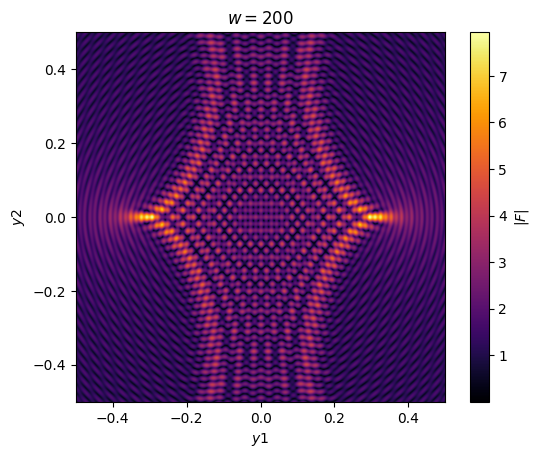

In [31]:
#import matplotlib.pyplot as plt
x = np.linspace(-0.5, 0.5, 10000)
Y1, Y2 = np.meshgrid(x,x)
#w = np.logspace(-3, 2, 1000)
w= 200
t1 = time.perf_counter(); Fm = amplification_map(w, Y1, Y2, lens)
print(f"many y : {Y1.size} source positions at one w    {time.perf_counter() - t1:.2f} s")
lens = point_mass(0.5, (-0.5, 0.0)) + point_mass(0.5, (0.5, 0.0)) 
plt.imshow(np.abs(amplification_map(w, Y1, Y2, lens)), extent=(-0.5, 0.5, -0.5, 0.5), origin='lower', cmap='inferno')
plt.colorbar(label='$|F|$')
plt.title(f'$ w={w}$')
plt.xlabel('$y1$')
plt.ylabel('$y2$')    

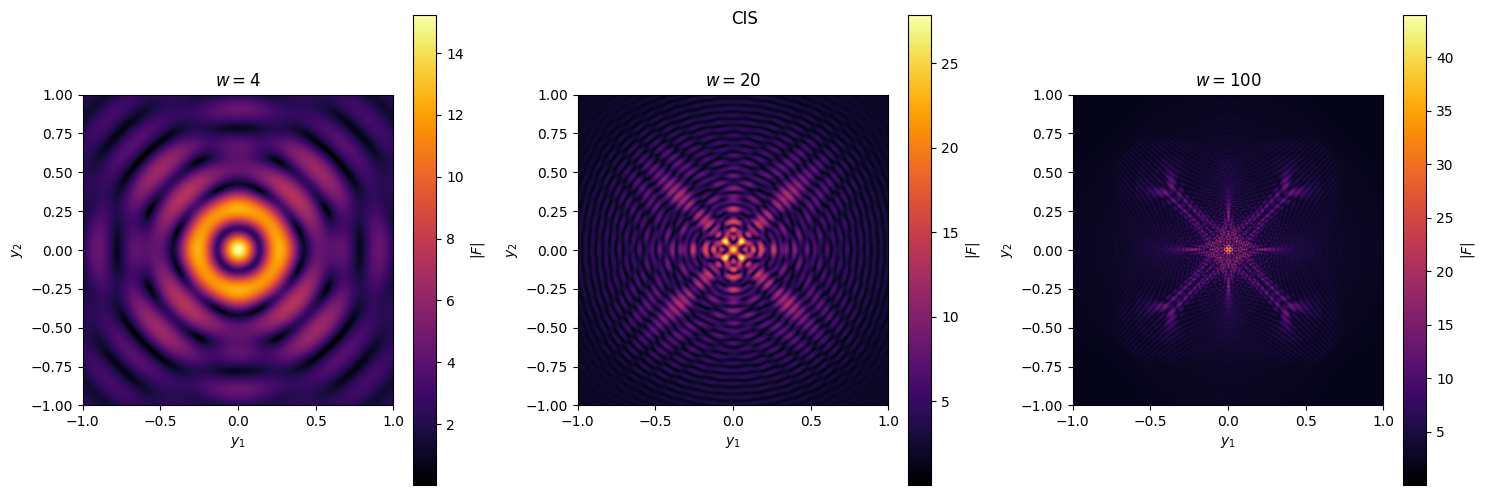

In [3]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1, 1, 500)
Y1, Y2 = np.meshgrid(x, x)

# Six values of w
w_values = [4,20,100] #np.logspace(1, 2, 6)
off = 2.0
#lens = point_mass(0.25, (-0.5, 0.0)) + point_mass(0.25, (0.5, 0.0))+ point_mass(0.25, (0.0, 0.5)) + point_mass(0.25, (0.0, -0.5))
lens = cis(psi0=1.0, rc=0.05, x0=(off, 0.0))+cis(psi0=1.0, rc=0.05, x0=(-off, 0))+cis(psi0=1.0, rc=0.05, x0=(0, off))+cis(psi0=1.0, rc=0.05, x0=(0.0, -off))
# Create 2 rows and 3 columns
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, w in zip(axes.flat, w_values):

    F = np.abs(amplification_map(w, Y1, Y2, lens))

    im = ax.imshow(
        F,
        extent=(-1, 1, -1, 1),
        cmap='inferno'
    )

    ax.set_title(f'$w = {w:.3g}$')
    ax.set_xlabel('$y_1$')
    ax.set_ylabel('$y_2$')

    fig.colorbar(im, ax=ax, label='$|F|$')

plt.tight_layout()
plt.suptitle('CIS')
plt.show()

Text(0, 0.5, '|F|')

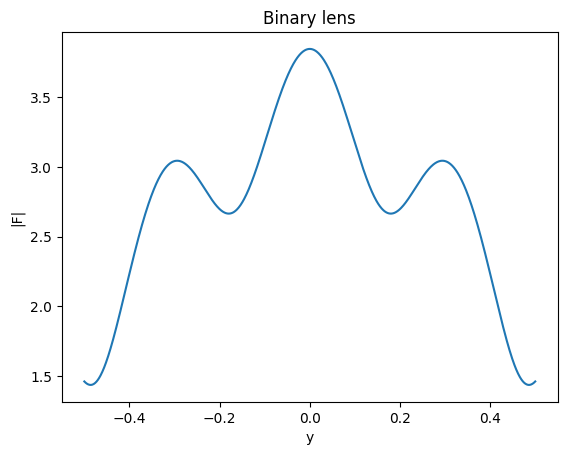

In [4]:
import matplotlib.pyplot as plt
w_val = np.linspace(0.1, 100, 1000)
y_val = np.linspace(-0.5, 0.5, 1000)
lens1  = point_mass(0.5, (-0.5, 0.0)) + point_mass(0.5, (0.5, 0.0))
F_val = []
for i in y_val:
    F_val.append(amplification(10, (i,0), lens1))
plt.plot(y_val, np.abs(F_val))
plt.title('Binary lens')
plt.xlabel('y')
plt.ylabel('|F|')

Time taken for amplification_many: 0.11 seconds


Text(0, 0.5, '|F|')

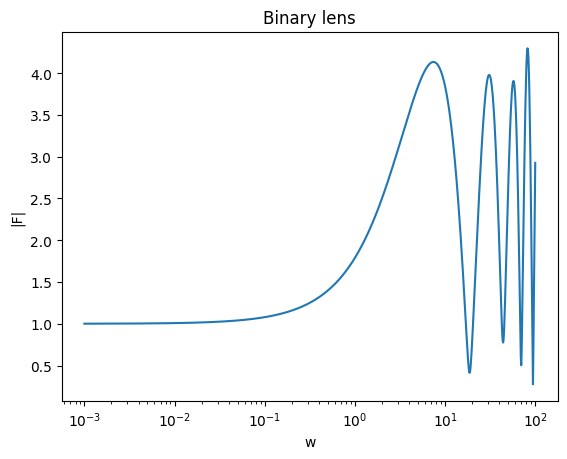

In [20]:
import time
w_val = np.logspace(-3, 2, 1000)
off =0.1
#lens = cis(psi0=1.0, rc=0.05, x0=(off, 0.0))+cis(psi0=1.0, rc=0.05, x0=(-off, 0))+cis(psi0=1.0, rc=0.05, x0=(0, off))+cis(psi0=1.0, rc=0.05, x0=(0.0, -off))
lens= point_mass(0.5, (-0.5, 0.0)) + point_mass(0.5, (0.5, 0.0))
start_time = time.time()
F = amplification_many(w_val, (0.0, 0.0), lens,n_workers=3)
end_time = time.time()
print(f"Time taken for amplification_many: {end_time - start_time:.2f} seconds")
plt.semilogx(w_val, np.abs(F))
plt.title('Binary lens')
plt.xlabel('w')
plt.ylabel('|F|')   
